In [1]:
!pip -q install kaggle

In [2]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle token: ")

Paste your Kaggle token: ··········


In [3]:
!kaggle datasets download -d imakash3011/customer-personality-analysis -p /content

Dataset URL: https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
License(s): CC0-1.0
100% 62.0k/62.0k [00:00<00:00, 32.2MB/s]



In [4]:
!unzip -oq /content/customer-personality-analysis.zip -d /content/marketing_data

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:

import pandas as pd

# Load the dataset
df = pd.read_csv(
    "/content/marketing_data/marketing_campaign.csv",
    sep="\t"
)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe())

print("\nDataset info:")
df.info()

print("\nUnique values in categorical columns:")
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

print("\nMarketing campaign response distribution:")
if "Response" in df.columns:
    print(df["Response"].value_counts())
    print(df["Response"].value_counts(normalize=True) * 100)


Dataset shape: (2240, 29)

First 5 rows:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0



Column names:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

Data types:
ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          in

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    22

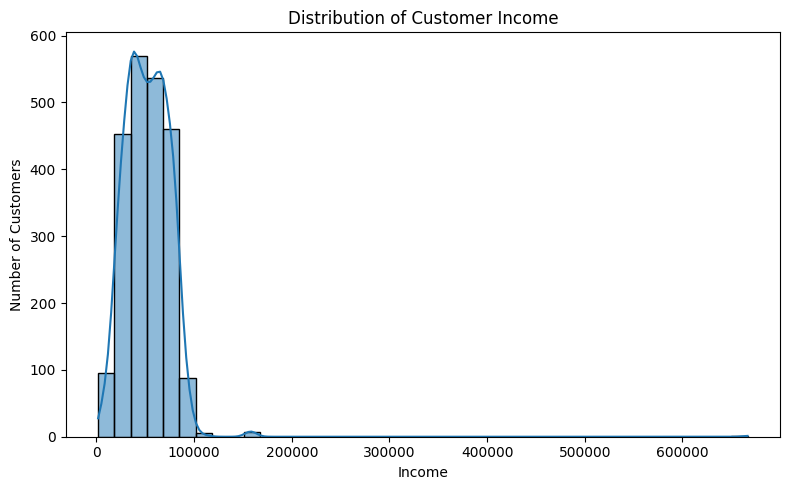

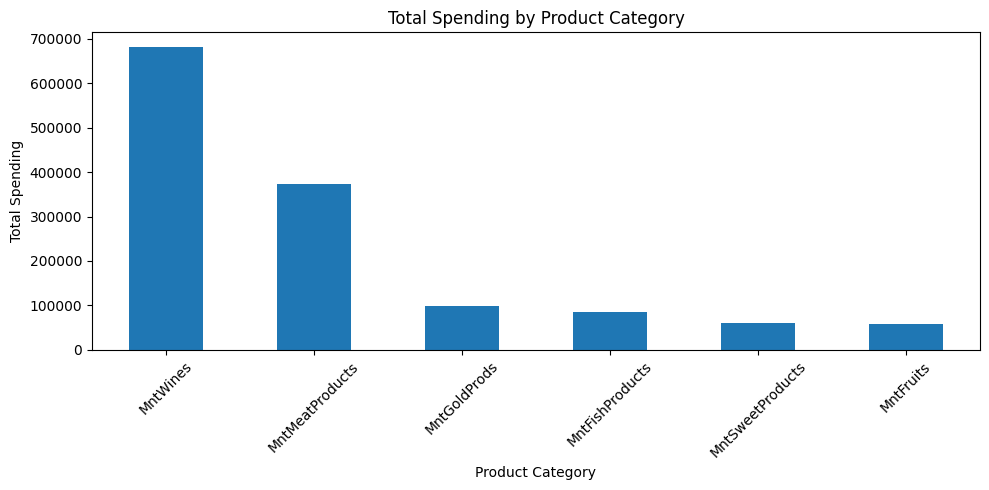

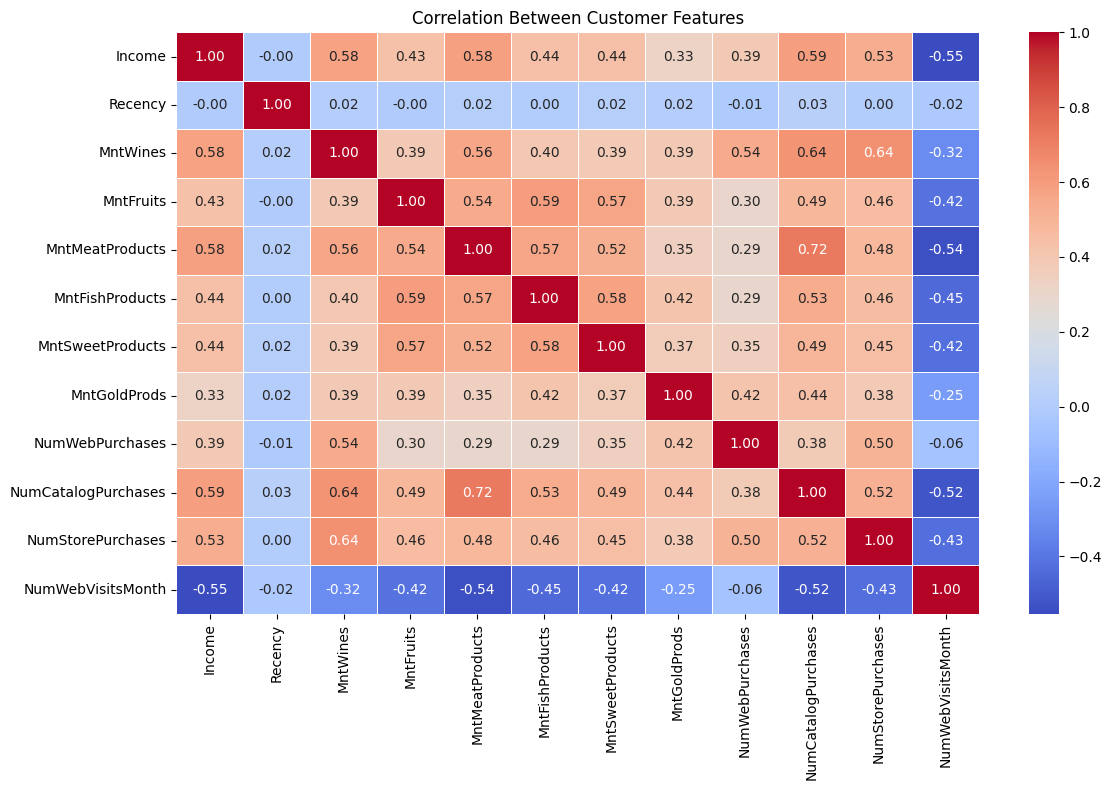

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select important numerical features
numeric_features = [
    "Income",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

# 1. Distribution of customer income
plt.figure(figsize=(8, 5))
sns.histplot(df["Income"].dropna(), bins=40, kde=True)
plt.title("Distribution of Customer Income")
plt.xlabel("Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 2. Distribution of spending on different products
spending_features = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

plt.figure(figsize=(10, 5))
df[spending_features].sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Total Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)
plt.title("Correlation Between Customer Features")
plt.tight_layout()
plt.show()


**EDA Interpretation:**

Customer income is right-skewed, with a few unusually high values. Wine and meat products account for the highest total spending. Income shows positive correlations with wine spending and catalog purchases, while monthly web visits are negatively correlated with income. These patterns can help identify meaningful customer segments.

In [9]:
import numpy as np

# Check numerical features for high correlations
corr_matrix = df.select_dtypes(include="number").corr()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle.stack()
    .loc[lambda x: x.abs() >= 0.70]
    .sort_values(key=abs, ascending=False)
)

print("Highly correlated feature pairs (|correlation| >= 0.70):")
display(high_corr)


Highly correlated feature pairs (|correlation| >= 0.70):


,,0
MntMeatProducts,NumCatalogPurchases,0.723827


In [10]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

# Create a copy
df_clean = df.copy()

# Remove identifiers and columns not used to form clusters
columns_to_drop = [
    "ID", "Dt_Customer",
    "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
    "AcceptedCmp4", "AcceptedCmp5",
    "Response", "Complain",
    "Z_CostContact", "Z_Revenue"
]
df_clean.drop(columns=columns_to_drop, inplace=True)

# Handle missing income values
df_clean["Income"] = df_clean["Income"].fillna(
    df_clean["Income"].median()
)

# Create age using 2014 as the reference year
df_clean["Age"] = 2014 - df_clean["Year_Birth"]
df_clean.drop(columns=["Year_Birth"], inplace=True)

# Remove implausible ages
df_clean = df_clean[df_clean["Age"].between(18, 100)].copy()

# Combine children and teenagers
df_clean["Children"] = df_clean["Kidhome"] + df_clean["Teenhome"]
df_clean.drop(columns=["Kidhome", "Teenhome"], inplace=True)

# Encode categorical variables
df_clean = pd.get_dummies(
    df_clean,
    columns=["Education", "Marital_Status"],
    dtype=int
)

print("Cleaned dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
display(df_clean.head())


Cleaned dataset shape: (2237, 28)
Missing values: 0


,Income,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,58138.0,58,635,88,546,172,88,88,3,8,...,0,0,0,0,0,0,1,0,0,0
1,46344.0,38,11,1,6,2,1,6,2,1,...,0,0,0,0,0,0,1,0,0,0
2,71613.0,26,426,49,127,111,21,42,1,8,...,0,0,0,0,0,0,0,1,0,0
3,26646.0,26,11,4,20,10,3,5,2,2,...,0,0,0,0,0,0,0,1,0,0
4,58293.0,94,173,43,118,46,27,15,5,5,...,0,1,0,0,0,1,0,0,0,0


One-Hot Encoding converts categorical variables like Education and Marital Status into numerical columns for clustering. Age is calculated using 2014 as the reference year for easier interpretation, and `Year_Birth` is removed to avoid redundant information. Ages outside 18–100 are filtered out to remove potentially implausible records.

In [11]:
import numpy as np

print("Highest 10 income values:")
display(df["Income"].nlargest(10))

Q1 = df["Income"].quantile(0.25)
Q3 = df["Income"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower IQR bound:", lower_bound)
print("Upper IQR bound:", upper_bound)

outliers = df[
    (df["Income"] < lower_bound) |
    (df["Income"] > upper_bound)
]

print("Number of income outliers:", len(outliers))

Highest 10 income values:


,Income
2233,666666.0
617,162397.0
687,160803.0
1300,157733.0
164,157243.0
1653,157146.0
2132,156924.0
655,153924.0
1898,113734.0
646,105471.0


Lower IQR bound: -14525.5
Upper IQR bound: 118350.5
Number of income outliers: 8


Interpretation: The Income column contains 8 outliers above the upper IQR bound of 118,350.5. The maximum value of 666,666 is unusually high and may affect distance-based clustering. Therefore, we should handle extreme income values before applying feature scaling and clustering.

In [12]:
Q1 = df_clean["Income"].quantile(0.25)
Q3 = df_clean["Income"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df_clean["Income"] = df_clean["Income"].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Income outliers capped.")
print(df_clean["Income"].describe())

Income outliers capped.
count      2237.000000
mean      51854.814037
std       20936.241476
min        1730.000000
25%       35523.000000
50%       51381.500000
75%       68281.000000
max      117418.000000
Name: Income, dtype: float64


Income capping was performed using the IQR method to limit extreme income values while retaining all customer records. This reduces the influence of unusually high incomes on distance-based clustering algorithms such as K-Means and DBSCAN, although it may reduce differences among high-income customers.

In [13]:
df_clean.columns

Index(['Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'Age', 'Children',
       'Education_2n Cycle', 'Education_Basic', 'Education_Graduation',
       'Education_Master', 'Education_PhD', 'Marital_Status_Absurd',
       'Marital_Status_Alone', 'Marital_Status_Divorced',
       'Marital_Status_Married', 'Marital_Status_Single',
       'Marital_Status_Together', 'Marital_Status_Widow',
       'Marital_Status_YOLO'],
      dtype='object')

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)

print("Number of customers:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])
print("Scaling completed successfully.")

Number of customers: 2237
Number of features: 28
Scaling completed successfully.


StandardScaler was used to standardize the 28 features to a common scale, with a mean of approximately 0 and a standard deviation of 1. This prevents features with larger numerical values, such as income and spending, from dominating distance calculations in K-Means and DBSCAN, helping identify meaningful customer clusters.

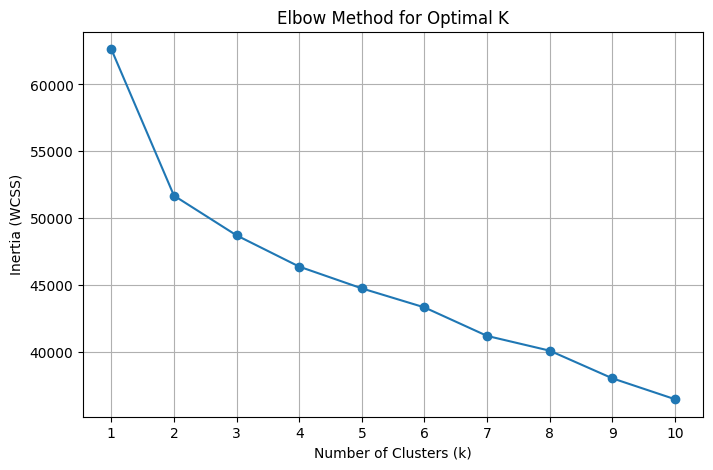

In [15]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Interpretation: The Elbow Method shows a sharp decrease in WCSS from \\(k=1\\) to \\(k=2\\), followed by a gradual decline as the number of clusters increases. The elbow appears around \\(k=2\\) or \\(k=3\\), suggesting these as possible cluster counts. The Silhouette Score should be compared for different values of \\(k\\) to select a suitable number of clusters.

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores[k] = score

    print(f"k = {k}, Silhouette Score = {score:.4f}")

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\nBest k based on Silhouette Score: {best_k}")

k = 2, Silhouette Score = 0.2001
k = 3, Silhouette Score = 0.1269
k = 4, Silhouette Score = 0.1463
k = 5, Silhouette Score = 0.1406
k = 6, Silhouette Score = 0.1071

Best k based on Silhouette Score: 2


In [17]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist

results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    centers = model.cluster_centers_

    # Average distance of customers from their own cluster center
    intra_distances = []
    for cluster in range(k):
        points = X_scaled[labels == cluster]
        distances = cdist(points, [centers[cluster]]).ravel()
        intra_distances.extend(distances)

    avg_intra = np.mean(intra_distances)

    # Average distance between different cluster centers
    center_distances = cdist(centers, centers)
    inter_distances = center_distances[
        np.triu_indices(k, k=1)
    ]
    avg_inter = np.mean(inter_distances)

    silhouette = silhouette_score(X_scaled, labels)

    results.append({
        "k": k,
        "Intra-cluster Distance": round(avg_intra, 4),
        "Inter-cluster Center Distance": round(avg_inter, 4),
        "Silhouette Score": round(silhouette, 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

,k,Intra-cluster Distance,Inter-cluster Center Distance,Silhouette Score
0,2,4.4111,4.5374,0.2001
1,3,4.2651,4.2153,0.1269
2,4,4.1552,5.9867,0.1463
3,5,4.0587,5.8144,0.1406
4,6,3.9473,5.2614,0.1071


The Silhouette Score is highest for \\(k=2\\) (0.2001), indicating better overall cluster separation than the other tested values. Although \\(k=4\\) has the highest inter-cluster center distance (5.9867), \\(k=6\\) has the lowest intra-cluster distance (3.9473). Therefore, \\(k=2\\) was selected based on its highest Silhouette Score. However, the relatively low score suggests that the customer clusters are not strongly separated and may overlap.

In [18]:
from sklearn.cluster import KMeans

# Create the final K-Means model
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign customers to clusters
kmeans_labels = kmeans.fit_predict(X_scaled)

# Store cluster labels
df_clean["KMeans_Cluster"] = kmeans_labels

# Display cluster sizes
print("K-Means clustering completed successfully.")
print("\nCustomers in each cluster:")
print(df_clean["KMeans_Cluster"].value_counts().sort_index())

K-Means clustering completed successfully.

Customers in each cluster:
KMeans_Cluster
0    1366
1     871
Name: count, dtype: int64


Interpretation: K-Means successfully grouped the 2,237 customers into two clusters. Cluster 0 contains 1,366 customers (61.1%), while Cluster 1 contains 871 customers (38.9%). This indicates that the algorithm identified two customer segments of different sizes. Further analysis of their income, spending, and purchasing behavior is needed to understand the characteristics of each segment.

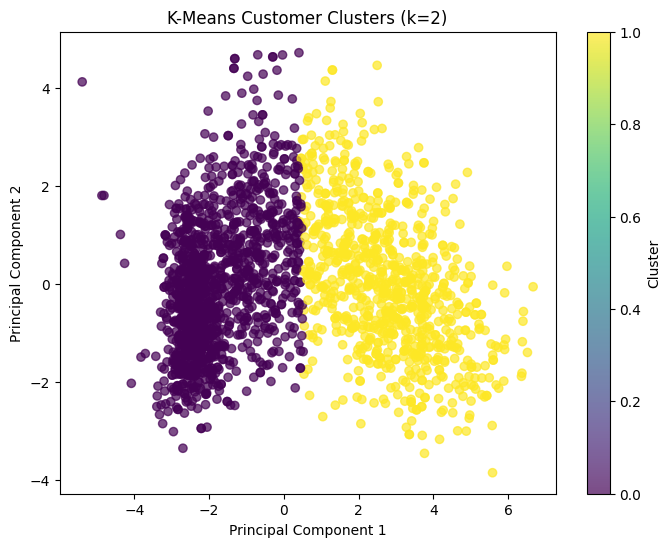

Explained variance by two components: 0.2902


In [19]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Clusters (k=2)")
plt.colorbar(label="Cluster")
plt.show()

print(
    "Explained variance by two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

PC1 shows the main differences between customers, while PC2 shows the second-most important differences. Together, they explain 29.02% of the variation in the customer data. The graph helps us visualize the two customer clusters, but it does not show all the information from the original dataset.

In [20]:
# Compare customer characteristics by cluster
cluster_summary = df_clean.groupby("KMeans_Cluster").agg({
    "Income": "mean",
    "Age": "mean",
    "Children": "mean",
    "MntWines": "mean",
    "MntMeatProducts": "mean",
    "NumWebPurchases": "mean",
    "NumStorePurchases": "mean",
    "NumWebVisitsMonth": "mean"
}).round(2)

display(cluster_summary)

,Income,Age,Children,MntWines,MntMeatProducts,NumWebPurchases,NumStorePurchases,NumWebVisitsMonth
KMeans_Cluster,,,,,,,,
0,39327.55,44.09,1.25,114.20,38.40,3.01,4.01,6.42
1,71501.48,46.68,0.48,601.66,368.47,5.77,8.60,3.60


Interpretation: Cluster 0 represents lower-income customers who spend less on wine and meat products, make fewer purchases, and visit websites more frequently. Cluster 1 represents higher-income customers who spend more on wine and meat products, make more online and in-store purchases, and visit websites less frequently. Both groups have similar average ages, but Cluster 1 has fewer children on average. These results show two distinct customer segments based on income and purchasing behavior.
Customers in Cluster 0 have more children at home on average than customers in Cluster 1.

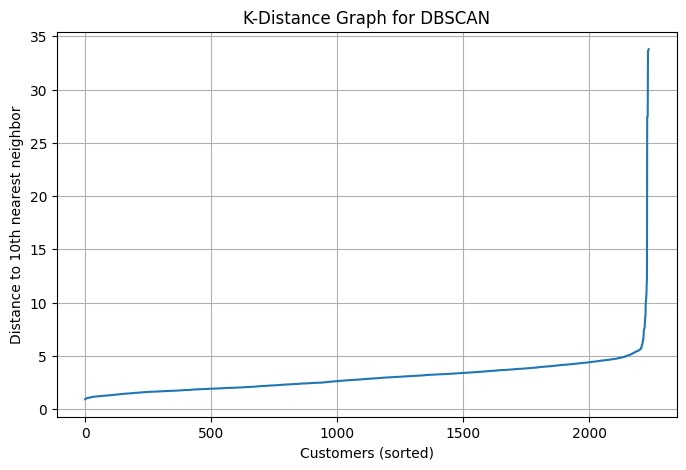

In [21]:
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import numpy as np

min_samples = 10

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Customers (sorted)")
plt.ylabel("Distance to 10th nearest neighbor")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()

Interpretation: The k-distance graph increases gradually for most customers, then rises sharply near the end. The bend appears around a distance of 5–6, suggesting that an eps value in this range may be worth testing for DBSCAN. We should compare the resulting clusters and noise points to choose a suitable value.

In [22]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np

dbscan = DBSCAN(eps=5.5, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

df_clean["DBSCAN_Cluster"] = dbscan_labels

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = np.sum(dbscan_labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("\nCustomers in each cluster:")
print(df_clean["DBSCAN_Cluster"].value_counts().sort_index())

# Silhouette Score, excluding noise points
mask = dbscan_labels != -1
valid_labels = dbscan_labels[mask]

if len(set(valid_labels)) >= 2:
    score = silhouette_score(X_scaled[mask], valid_labels)
    print("\nSilhouette Score (excluding noise):", round(score, 4))
else:
    print("\nSilhouette Score cannot be calculated: fewer than 2 non-noise clusters.")

Number of clusters: 3
Number of noise points: 24

Customers in each cluster:
DBSCAN_Cluster
-1      24
 0    2085
 1      52
 2      76
Name: count, dtype: int64

Silhouette Score (excluding noise): 0.2345


Interpretation of DBSCAN results
DBSCAN identified 3 clusters and marked 24 customers as noise (outliers). Cluster 0 contains 2,085 customers, Cluster 1 contains 52, and Cluster 2 contains 76. The Silhouette Score is 0.2345 after excluding noise points, suggesting modest separation among the non-noise clusters. However, most customers belong to Cluster 0, so the clustering is highly imbalanced.

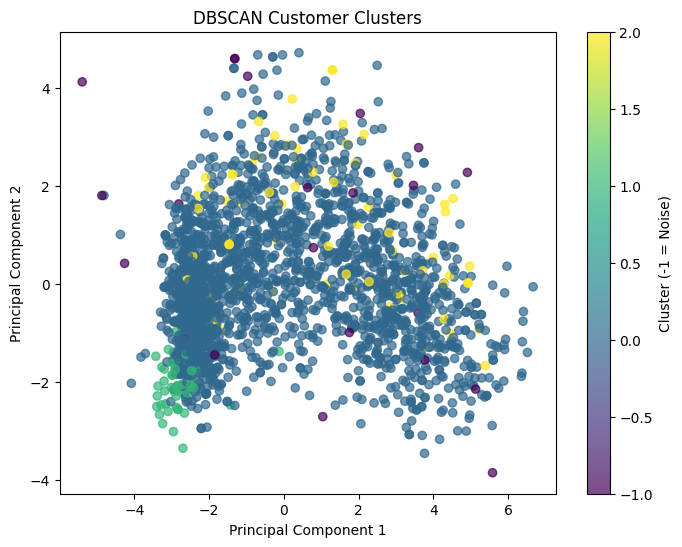

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Customer Clusters")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.show()

Interpretation for your report: The DBSCAN visualization displays three identified customer clusters and noise points, labeled -1. The clusters may differ in size and distribution, with most customers assigned to the main cluster. The PCA plot represents only 29.02% of the total data variance, so some cluster separation may not be visible in this two-dimensional visualization.

In [27]:
print("K-Means")
print("Number of clusters:", len(set(kmeans_labels)))
print("Silhouette Score:", round(silhouette_score(X_scaled, kmeans_labels), 4))

print("\nDBSCAN")
print("Number of clusters:", len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))
print("Noise points:", (dbscan_labels == -1).sum())
print("Silhouette Score (excluding noise):", 0.2345)

K-Means
Number of clusters: 2
Silhouette Score: 0.2001

DBSCAN
Number of clusters: 3
Noise points: 24
Silhouette Score (excluding noise): 0.2345


Interpretation: K-Means vs DBSCAN
K-Means identified 2 clusters with a Silhouette Score of 0.2001, while DBSCAN identified 3 clusters with a Silhouette Score of 0.2345, excluding 24 noise points. DBSCAN achieved a slightly higher Silhouette Score, suggesting better separation among the customers assigned to its clusters. However, DBSCAN placed most customers in one large cluster, so both the score and cluster distribution should be considered when comparing the algorithms.

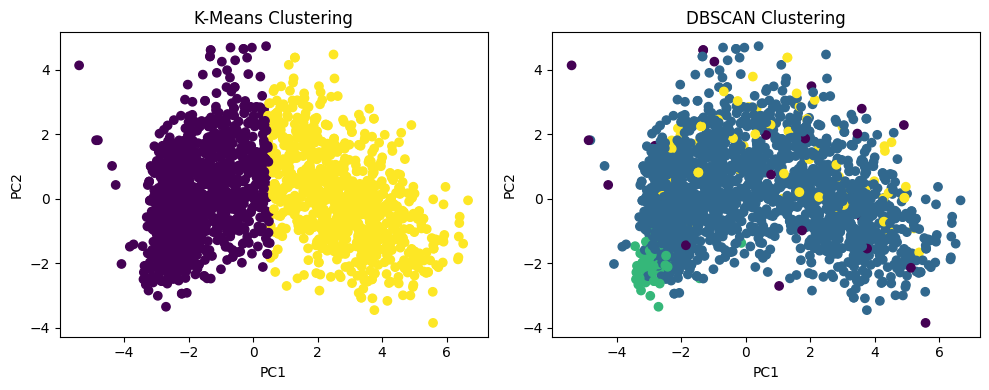

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis")
plt.title("K-Means Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap="viridis")
plt.title("DBSCAN Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()

In [30]:
print("Cleaned data:", df_clean.shape)
print("Scaled data:", X_scaled.shape)
print("K-Means labels:", len(kmeans_labels))
print("DBSCAN labels:", len(dbscan_labels))

print("\nK-Means clusters:")
print(df_clean["KMeans_Cluster"].value_counts())

print("\nDBSCAN clusters:")
print(df_clean["DBSCAN_Cluster"].value_counts())

Cleaned data: (2237, 30)
Scaled data: (2237, 28)
K-Means labels: 2237
DBSCAN labels: 2237

K-Means clusters:
KMeans_Cluster
0    1366
1     871
Name: count, dtype: int64

DBSCAN clusters:
DBSCAN_Cluster
 0    2085
 2      76
 1      52
-1      24
Name: count, dtype: int64


In [31]:
print("K-Means model:", kmeans)
print("Number of clusters:", kmeans.n_clusters)
print("Number of features:", kmeans.n_features_in_)
print("Scaler feature count:", scaler.n_features_in_)
print("Cluster centers shape:", kmeans.cluster_centers_.shape)

K-Means model: KMeans(n_clusters=2, n_init=10, random_state=42)
Number of clusters: 2
Number of features: 28
Scaler feature count: 28
Cluster centers shape: (2, 28)


In [32]:
# Predict clusters for the existing scaled data
test_predictions = kmeans.predict(X_scaled)

print("Total predictions:", len(test_predictions))
print("Predictions successful:", len(test_predictions) == len(X_scaled))
print("Cluster counts:")
print(pd.Series(test_predictions).value_counts().sort_index())

print("Predictions match existing labels:",
      np.array_equal(test_predictions, kmeans_labels))

Total predictions: 2237
Predictions successful: True
Cluster counts:
0    1366
1     871
Name: count, dtype: int64
Predictions match existing labels: True


### Interpretation of the K-Means prediction results

The K-Means model successfully predicted cluster assignments for all 2,237 customers in the preprocessed dataset. It assigned 1,366 customers to Cluster 0 and 871 customers to Cluster 1, matching the cluster assignments obtained during model training.

The result `Predictions successful: True` confirms that the model generated a prediction for every customer. Similarly, `Predictions match existing labels: True` indicates that the model consistently assigned the same customers to the same clusters when predicting on the training data.

This confirms that the fitted model is functioning as expected. However, it does not mean that the model has 100% accuracy, because K-Means is an unsupervised learning algorithm and the predictions were made on the same data used for training. Testing with new customer records is still required before deployment.

In [33]:
import joblib

# Save the fitted model and scaler
joblib.dump(kmeans, "kmeans_customer_model.pkl")
joblib.dump(scaler, "customer_scaler.pkl")

print("K-Means model saved successfully!")
print("StandardScaler saved successfully!")

K-Means model saved successfully!
StandardScaler saved successfully!


In [34]:
from google.colab import files

# Download the trained K-Means model
files.download("kmeans_customer_model.pkl")

# Download the fitted scaler
files.download("customer_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import joblib
from google.colab import files

# Save the fitted DBSCAN model
joblib.dump(dbscan, "dbscan_customer_model.pkl")

# Download the saved model
files.download("dbscan_customer_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import joblib
import numpy as np
import pandas as pd

# Load the saved models
loaded_kmeans = joblib.load("kmeans_customer_model.pkl")
loaded_scaler = joblib.load("customer_scaler.pkl")
loaded_dbscan = joblib.load("dbscan_customer_model.pkl")

# Verify K-Means predictions
loaded_predictions = loaded_kmeans.predict(X_scaled)

print("K-Means model loaded:", loaded_kmeans.n_clusters == 2)
print("Scaler loaded:", loaded_scaler.n_features_in_ == 28)
print("DBSCAN model loaded:", hasattr(loaded_dbscan, "labels_"))
print(
    "K-Means predictions match:",
    np.array_equal(loaded_predictions, kmeans_labels)
)

K-Means model loaded: True
Scaler loaded: True
DBSCAN model loaded: True
K-Means predictions match: True


In [37]:
import joblib

# Save the feature names and their exact order
joblib.dump(list(df_clean.drop(
    columns=["KMeans_Cluster", "DBSCAN_Cluster"],
    errors="ignore"
).columns), "customer_feature_names.pkl")

print("Feature names saved successfully!")

Feature names saved successfully!


In [38]:
import joblib

feature_names = joblib.load("customer_feature_names.pkl")

print("Number of features:", len(feature_names))
print("Feature names in training order:")
print(feature_names)

print("\nMatches scaled data:",
      len(feature_names) == X_scaled.shape[1])

Number of features: 28
Feature names in training order:
['Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Age', 'Children', 'Education_2n Cycle', 'Education_Basic', 'Education_Graduation', 'Education_Master', 'Education_PhD', 'Marital_Status_Absurd', 'Marital_Status_Alone', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow', 'Marital_Status_YOLO']

Matches scaled data: True


This matters because K-Means expects the same feature order during prediction as it received during training.

In [39]:
import joblib
import zipfile
import os

# Files needed for the initial K-Means deployment
files_to_package = [
    "kmeans_customer_model.pkl",
    "customer_scaler.pkl",
    "customer_feature_names.pkl"
]

# Verify all required files exist
for file in files_to_package:
    if not os.path.exists(file):
        raise FileNotFoundError(f"Missing file: {file}")

# Create a ZIP package
with zipfile.ZipFile("customer_segmentation_model.zip", "w") as zipf:
    for file in files_to_package:
        zipf.write(file)

print("Deployment package created successfully!")
print("Files included:", files_to_package)

Deployment package created successfully!
Files included: ['kmeans_customer_model.pkl', 'customer_scaler.pkl', 'customer_feature_names.pkl']


In [40]:
import zipfile

with zipfile.ZipFile("customer_segmentation_model.zip", "r") as zipf:
    print("Files in deployment package:")
    for name in zipf.namelist():
        print(name)

    print("\nZIP integrity check:", zipf.testzip())

Files in deployment package:
kmeans_customer_model.pkl
customer_scaler.pkl
customer_feature_names.pkl

ZIP integrity check: None


In [41]:
from google.colab import files
files.download("customer_segmentation_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>